# 最適化結果の比較: comp_ew vs comp_ew × afats

`01_evaluation` で作った複合スコア `comp_ew_{90,80,70}_afats_{10,20,30}`（comp_ew と Theil–Sen 型 Agnostic スコアのサイズ・セクター中立化版
`agnostic_neu/afa_ts_neu` の Blom 加重和）を bax で最適化した結果（`bax/output/comp_ew_{w}_afats_{100−w}`）を、
`comp_ew` 単独の最適化結果と比較する。参考として、これまでの最有力候補 `comp_ew_70_ai_neu_30`（`experiments/my_ai/06_bax_results_neu`）も並べる。

**最適化条件**: `bc.txt` は comp_ew と入出力パス以外すべて同一（確認済み）。期間 201212〜202607、推定 TE ≤ 5%、個別 0〜10% / 対 BM ±3%、
業種 ±3%、リスクインデックス ±2sd、回転率 ≤ 15%/月、線形コスト 0.5%、ホライズン 12 か月、USD ニューメレール。

**評価期間の揃え方**: afats 複合スコアは 202606 までしか無く、afats 系の 202607 リバランスはアルファ無し（`gbax.log` に
`Failed to open .../alpha/202607.dat`）で回転率 0.6% の空リバランスになっている。bax の `st_prfm` は月 $t$ の行に
「月 $t$ のリターン」と「リバランス $t$ の売買コスト・回転率」を載せるため、202607 の行は比較に使えない。
**すべての系列を 202606 で打ち切って比較する**（税評価も同様。バーンイン 12 か月）。

制約なしの評価（`01_evaluation` §4–5）では、afats 複合は 80:20 が最良（Q5 EW 超過・IR が comp_ew を上回る）だった。
本ノートブックは、それが **制約付き最適化・税控除後でも** comp_ew を上回るかを確認する。

In [1]:
import japanize_matplotlib  # noqa: F401  日本語ラベル用
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from alphaeval import (
    InputStore,
    india_tax_schedule,
    performance_summary,
    portfolio_returns,
    quantile_analysis,
)
from alphaeval.bax import (
    BaxOutput,
    evaluate_bax,
    factor_attribution,
    risk_decomposition,
    summarize,
)

pd.set_option("display.width", 260)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

BAX_ROOT = "../../bax/output"
INPUT_ROOT = "../../input/msci_india_imi"
W = [90, 80, 70]
AFATS = [f"comp_ew_{w}_afats_{100 - w}" for w in W]
REF = "comp_ew_70_ai_neu_30"
NAMES = ["comp_ew"] + AFATS + [REF]
SCORE_PATH = {n: f"composite/{n}" for n in NAMES}
SCORE_PATH["comp_ew"] = "composite/comp_ew"
BENCHMARK = "msci_india"
RISK_MODEL = "GEMLT"
FPI_TYPE = "trust"
BURN_IN = 12
END = pd.Timestamp("2026-06-30")  # afats の 202607 リバランスはアルファ無しのため除外
SECTOR_NAMES = {
    10: "エネルギー",
    15: "素材",
    20: "資本財",
    25: "一般消費財",
    30: "生活必需品",
    35: "ヘルスケア",
    40: "金融",
    45: "情報技術",
    50: "通信",
    55: "公益",
    60: "不動産",
}
COLORS = {"comp_ew": "k", AFATS[0]: "C0", AFATS[1]: "C1", AFATS[2]: "C2", REF: "C7"}

store = InputStore(INPUT_ROOT)


def nw_tstat(x: pd.Series, lags: int = 6) -> float:
    # 平均の Newey–West t 値（Bartlett カーネル）
    x = x.dropna().to_numpy()
    n = len(x)
    e = x - x.mean()
    v = e @ e / n
    for k in range(1, lags + 1):
        v += 2 * (1 - k / (lags + 1)) * (e[k:] @ e[:-k]) / n
    return x.mean() / np.sqrt(v / n)

## 1. 一括評価（税は INR 建てリターンで FIFO ロット台帳）

In [2]:
outs = {n: BaxOutput(f"{BAX_ROOT}/{n}") for n in NAMES}
first = outs["comp_ew"]
rtn_inr = store.returns(RISK_MODEL, "rtn")
gics = store.alpha("attributes/gics")
schedule = india_tax_schedule(FPI_TYPE)
results, tables, tax_tables = {}, {}, {}
for n, out in outs.items():
    sector = (
        (gics // 1_000_000)
        .reindex(index=out.rebalance_dates)
        .apply(lambda c: c.map(SECTOR_NAMES))
    )
    results[n] = evaluate_bax(
        out, mapping=sector, tax_schedule=schedule, tax_returns=rtn_inr, burn_in=BURN_IN
    )
    tables[n] = results[n].table.loc[:END]
    tax_tables[n] = results[n].tax_table.loc[:END]
    print(
        f"{n:24s} {tables[n].dropna(subset=['fund']).index.min():%Y-%m} – {tables[n].index.max():%Y-%m}  税評価 {tax_tables[n].index.min():%Y-%m} –"
    )

comp_ew                  2013-01 – 2026-06  税評価 2013-12 –


/Users/inu/workspace/india/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/inu/workspace/india/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


comp_ew_90_afats_10      2013-01 – 2026-06  税評価 2013-12 –


/Users/inu/workspace/india/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/inu/workspace/india/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


comp_ew_80_afats_20      2013-01 – 2026-06  税評価 2013-12 –


/Users/inu/workspace/india/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/inu/workspace/india/.venv/lib/python3.12/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


comp_ew_70_afats_30      2013-01 – 2026-06  税評価 2013-12 –


comp_ew_70_ai_neu_30     2013-01 – 2026-06  税評価 2013-12 –


## 2. 基本指標（〜202606）

In [3]:
rows = {}
for n in NAMES:
    s = summarize(tables[n])
    tt = tax_tables[n]
    net = performance_summary(tt["fund_after_tax"], tt["bm"])
    pos_s, pos_l = (
        tt["gain_short"].clip(lower=0).sum(),
        tt["gain_long"].clip(lower=0).sum(),
    )
    rows[n] = {
        "超過 グロス": s["active_return_gross"],
        "超過 コスト後": s["active_return"],
        "超過 税後": net["active_return"],
        "TE 実現": s["tracking_error"],
        "TE 推定": s["omega_mean"],
        "実現/推定": s["te_ratio_realized_to_omega"],
        "IR コスト後": s["information_ratio"],
        "IR 税後": net["information_ratio"],
        "回転率": s["turnover_annual"],
        "コストドラッグ": s["cost_drag"],
        "税ドラッグ": s["active_return"] - net["active_return"],
        "短期比率": pos_s / (pos_s + pos_l) if pos_s + pos_l > 0 else np.nan,
        "勝率": s["hit_rate"],
        "最大DD 超過": s["max_drawdown_excess"],
        "銘柄数": s["n_hold_mean"],
        "アクティブシェア": s["active_share_mean"],
    }
tbl = pd.DataFrame(rows).T
display(tbl.round(3))
print("comp_ew との差")
display(
    (tbl - tbl.loc["comp_ew"])
    .drop(index="comp_ew")[
        [
            "超過 グロス",
            "超過 コスト後",
            "超過 税後",
            "IR コスト後",
            "IR 税後",
            "TE 実現",
            "回転率",
            "税ドラッグ",
            "最大DD 超過",
        ]
    ]
    .round(3)
)

,超過 グロス,超過 コスト後,超過 税後,TE 実現,TE 推定,実現/推定,IR コスト後,IR 税後,回転率,コストドラッグ,税ドラッグ,短期比率,勝率,最大DD 超過,銘柄数,アクティブシェア
comp_ew,0.066,0.057,0.043,0.061,0.049,1.240,0.927,0.691,1.125,0.010,0.014,0.458,0.667,-0.108,89.914,0.662
comp_ew_90_afats_10,0.066,0.056,0.043,0.062,0.049,1.265,0.905,0.677,1.125,0.010,0.014,0.451,0.642,-0.113,89.753,0.664
comp_ew_80_afats_20,0.065,0.055,0.042,0.064,0.049,1.304,0.865,0.644,1.119,0.010,0.014,0.432,0.636,-0.116,89.944,0.666
comp_ew_70_afats_30,0.063,0.054,0.040,0.066,0.049,1.337,0.818,0.608,1.105,0.010,0.014,0.414,0.623,-0.126,88.494,0.667
comp_ew_70_ai_neu_30,0.071,0.061,0.045,0.061,0.049,1.240,0.993,0.728,1.201,0.011,0.016,0.502,0.642,-0.102,94.667,0.670


comp_ew との差


,超過 グロス,超過 コスト後,超過 税後,IR コスト後,IR 税後,TE 実現,回転率,税ドラッグ,最大DD 超過
comp_ew_90_afats_10,-0.000,-0.000,-0.000,-0.022,-0.014,0.001,0.000,-0.000,-0.005
comp_ew_80_afats_20,-0.001,-0.001,-0.001,-0.063,-0.047,0.003,-0.006,0.000,-0.009
comp_ew_70_afats_30,-0.003,-0.003,-0.003,-0.109,-0.083,0.005,-0.019,-0.000,-0.019
comp_ew_70_ai_neu_30,0.005,0.004,0.002,0.066,0.037,0.000,0.076,0.002,0.005


## 3. comp_ew との月次差の検定

月次超過リターンの差 $d_t = r^{\text{blend}}_t - r^{\text{comp\_ew}}_t$ の年率平均（$\bar d \times 12$）、Newey–West（6 ラグ）t 値、
差の勝率（$d_t>0$ の割合）、差の標準偏差（年率、= comp_ew に対する相対 TE）、超過リターン同士の相関。期間はバーンイン後（税評価と同じ起点）。

差 年率   NW t   差の勝率   相対TE     相関   月数
基準   スコア                                                         
グロス  comp_ew_90_afats_10  -0.000 -0.110  0.477  0.008  0.992  151
     comp_ew_80_afats_20  -0.001 -0.258  0.483  0.017  0.965  151
     comp_ew_70_afats_30  -0.004 -0.420  0.490  0.026  0.923  151
     comp_ew_70_ai_neu_30  0.004  0.906  0.563  0.016  0.967  151
コスト後 comp_ew_90_afats_10  -0.000 -0.115  0.464  0.008  0.992  151
     comp_ew_80_afats_20  -0.001 -0.245  0.483  0.017  0.965  151
     comp_ew_70_afats_30  -0.003 -0.383  0.497  0.026  0.923  151
     comp_ew_70_ai_neu_30  0.003  0.712  0.523  0.016  0.967  151
税後   comp_ew_90_afats_10  -0.000 -0.047  0.477  0.008  0.992  151
     comp_ew_80_afats_20  -0.001 -0.220  0.477  0.017  0.966  151
     comp_ew_70_afats_30  -0.003 -0.327  0.483  0.026  0.920  151
     comp_ew_70_ai_neu_30  0.002  0.517  0.536  0.016  0.967  151

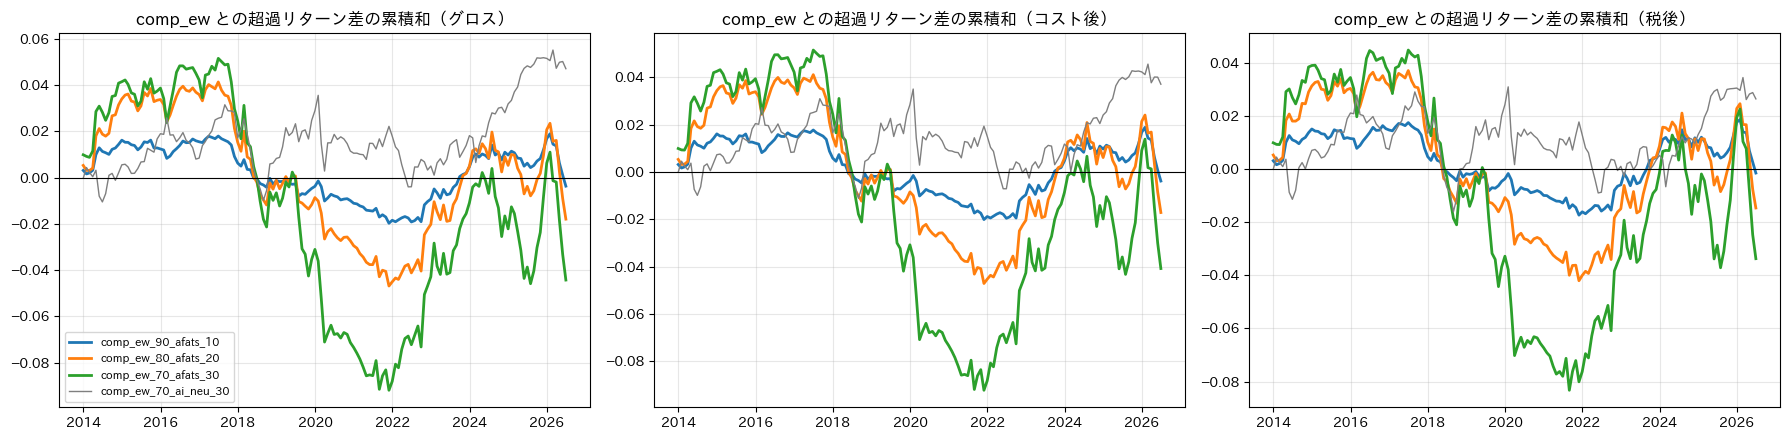

In [4]:
start = tax_tables["comp_ew"].index.min()
ex = {
    "グロス": pd.DataFrame({n: tables[n]["excess_gross"] for n in NAMES}).loc[start:],
    "コスト後": pd.DataFrame({n: tables[n]["excess"] for n in NAMES}).loc[start:],
    "税後": pd.DataFrame({n: tax_tables[n]["excess_after_tax"] for n in NAMES}).loc[
        start:
    ],
}
rows = []
for kind, df in ex.items():
    for n in NAMES[1:]:
        d = df[n] - df["comp_ew"]
        rows.append(
            {
                "基準": kind,
                "スコア": n,
                "差 年率": d.mean() * 12,
                "NW t": nw_tstat(d),
                "差の勝率": (d > 0).mean(),
                "相対TE": d.std() * np.sqrt(12),
                "相関": df[n].corr(df["comp_ew"]),
                "月数": d.notna().sum(),
            }
        )
diff_tbl = pd.DataFrame(rows).set_index(["基準", "スコア"])
display(diff_tbl.round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (kind, df) in zip(axes, ex.items()):
    for n in NAMES[1:]:
        ax.plot(
            df.index,
            (df[n] - df["comp_ew"]).cumsum(),
            label=n,
            color=COLORS[n],
            linewidth=2.0 if n in AFATS else 1.0,
        )
    ax.axhline(0, color="k", linewidth=0.8)
    ax.set_title(f"comp_ew との超過リターン差の累積和（{kind}）")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. 累積超過リターン

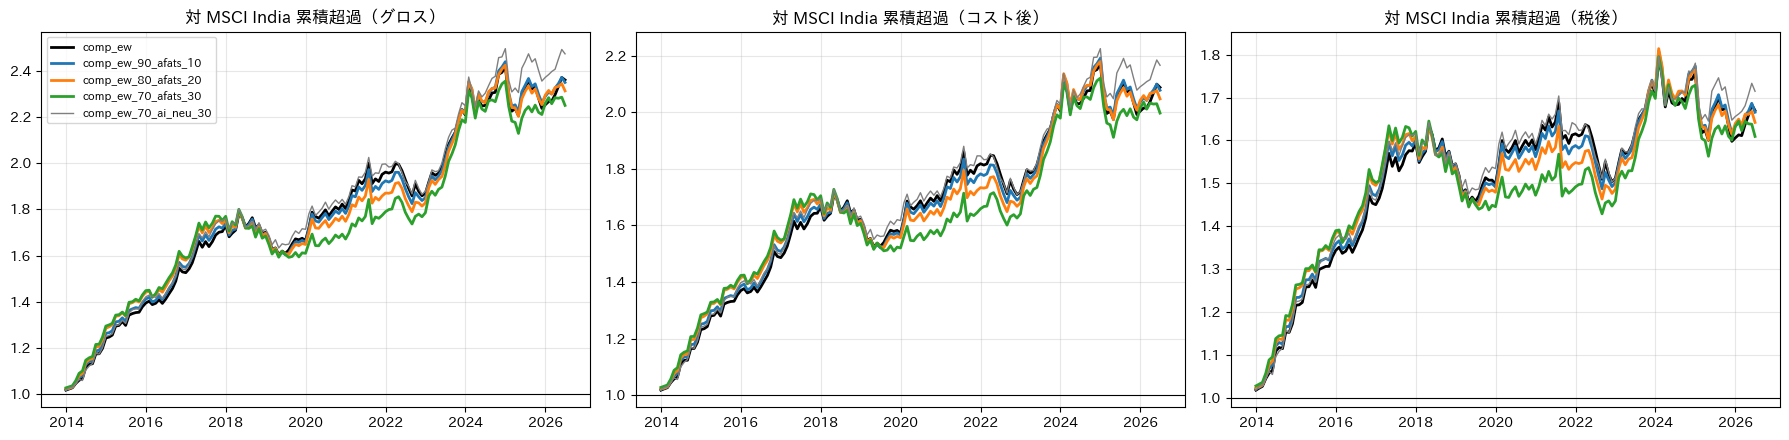

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (kind, df) in zip(axes, ex.items()):
    for n in NAMES:
        ax.plot(
            df.index,
            (1 + df[n]).cumprod(),
            label=n,
            color=COLORS[n],
            linewidth=2.0 if n in ["comp_ew"] + AFATS else 1.0,
        )
    ax.axhline(1, color="k", linewidth=0.8)
    ax.set_title(f"対 MSCI India 累積超過（{kind}）")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. 期間別（前半 2014–2019 / 後半 2020–2026.06）と年別

前半 2014–2019                       後半 2020–2026.06                      
                              グロス     税後 IR コスト後  IR 税後             グロス     税後 IR コスト後  IR 税後
comp_ew                     0.084  0.066   1.312  1.189           0.056  0.019   0.678  0.283
comp_ew_90_afats_10         0.083  0.065   1.245  1.126           0.056  0.019   0.673  0.287
comp_ew_80_afats_20         0.081  0.063   1.164  1.045           0.055  0.018   0.645  0.271
comp_ew_70_afats_30         0.077  0.059   1.041  0.930           0.054  0.019   0.640  0.278
comp_ew_70_ai_neu_30        0.089  0.070   1.381  1.256           0.059  0.019   0.701  0.291

年別 超過（コスト後, 複利）


,comp_ew,comp_ew_90_afats_10,comp_ew_80_afats_20,comp_ew_70_afats_30,comp_ew_70_ai_neu_30
2013,0.018,0.021,0.023,0.028,0.018
2014,0.210,0.225,0.245,0.249,0.219
2015,0.112,0.108,0.111,0.108,0.127
2016,0.085,0.088,0.087,0.088,0.072
2017,0.122,0.111,0.098,0.101,0.131
2018,-0.027,-0.035,-0.043,-0.057,-0.036
2019,-0.030,-0.032,-0.037,-0.054,-0.010
2020,0.073,0.065,0.050,0.028,0.052
2021,0.078,0.069,0.060,0.061,0.085
2022,-0.055,-0.046,-0.031,-0.011,-0.068


comp_ew との差（年別）、comp_ew を上回った年数: {'comp_ew_90_afats_10': 7, 'comp_ew_80_afats_20': 6, 'comp_ew_70_afats_30': 6, 'comp_ew_70_ai_neu_30': 8}


,comp_ew_90_afats_10,comp_ew_80_afats_20,comp_ew_70_afats_30,comp_ew_70_ai_neu_30
2013,0.003,0.005,0.010,-0.000
2014,0.015,0.035,0.039,0.009
2015,-0.004,-0.001,-0.004,0.015
2016,0.003,0.002,0.003,-0.013
2017,-0.010,-0.023,-0.020,0.009
2018,-0.007,-0.016,-0.030,-0.009
2019,-0.002,-0.007,-0.024,0.021
2020,-0.008,-0.022,-0.044,-0.021
2021,-0.008,-0.018,-0.017,0.007
2022,0.009,0.024,0.044,-0.013


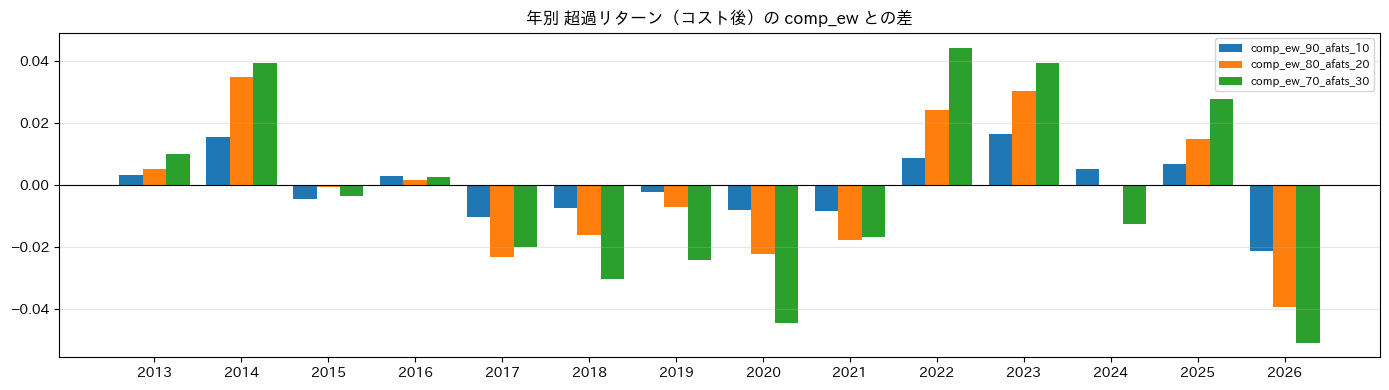

In [6]:
periods = {
    "前半 2014–2019": ("2014-01-01", "2019-12-31"),
    "後半 2020–2026.06": ("2020-01-01", "2026-06-30"),
}
rows = {}
for n in NAMES:
    r = {}
    for p, (a, b) in periods.items():
        g = ex["グロス"][n].loc[a:b]
        c = ex["コスト後"][n].loc[a:b]
        t = ex["税後"][n].loc[a:b]
        r[(p, "グロス")] = g.mean() * 12
        r[(p, "税後")] = t.mean() * 12
        r[(p, "IR コスト後")] = c.mean() * 12 / (c.std() * np.sqrt(12))
        r[(p, "IR 税後")] = t.mean() * 12 / (t.std() * np.sqrt(12))
    rows[n] = r
period_tbl = pd.DataFrame(rows).T
display(period_tbl.round(3))

yearly = pd.DataFrame(
    {
        n: ex["コスト後"][n]
        .groupby(ex["コスト後"].index.year)
        .apply(lambda x: (1 + x).prod() - 1)
        for n in NAMES
    }
)
yearly_diff = yearly[NAMES[1:]].sub(yearly["comp_ew"], axis=0)
print("年別 超過（コスト後, 複利）")
display(yearly.round(3))
print(
    "comp_ew との差（年別）、comp_ew を上回った年数:", (yearly_diff > 0).sum().to_dict()
)
display(yearly_diff.round(3))

fig, ax = plt.subplots(figsize=(14, 4))
x = np.arange(len(yearly_diff))
for i, n in enumerate(AFATS):
    ax.bar(x + (i - 1) * 0.27, yearly_diff[n], width=0.27, label=n, color=COLORS[n])
ax.set_xticks(x, yearly_diff.index)
ax.axhline(0, color="k", linewidth=0.8)
ax.set_title("年別 超過リターン（コスト後）の comp_ew との差")
ax.legend(fontsize=8)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## 6. 制約の張り付きとアルファの効き方

In [7]:
rows = {}
for n, out in outs.items():
    obj = out.objective().iloc[1:].loc[:END]
    perf = out.performance().iloc[1:].loc[:END]
    h = results[n].holdings.loc[:END]
    ind = results[n].exposures["industry"]
    rows[n] = {
        "omega 平均": obj["omega"].mean(),
        "omega ≥ 4.9% の月": (obj["omega"] >= 0.049).mean(),
        "回転率 ≥ 14.9% の月": (perf["rot"] >= 0.149).mean(),
        "回転率 平均/月": perf["rot"].mean(),
        "業種 下限張り付き（平均本数）": ind["at_lower"].sum(),
        "業種 上限張り付き（平均本数）": ind["at_upper"].sum(),
        "個別 上限張り付き（平均）": h["n_at_upper"].mean(),
        "個別 下限張り付き（平均）": h["n_at_lower"].mean(),
        "アルファ（opt 加重）": h["alpha_weighted"].mean(),
        "アルファ（BM 加重）": h["alpha_bm_weighted"].mean(),
    }
display(pd.DataFrame(rows).T.round(3))

# comp_ew とのポートフォリオの重なり（リバランス日ごとのウェイト差の片道合計）
w0 = outs["comp_ew"].holdings_panel("wgt_o").fillna(0.0).loc[:END]
rows = {}
for n in NAMES[1:]:
    w1 = outs[n].holdings_panel("wgt_o").fillna(0.0).loc[:END]
    cols = w0.columns.union(w1.columns)
    d = (
        w1.reindex(columns=cols, fill_value=0.0)
        - w0.reindex(index=w1.index, columns=cols, fill_value=0.0)
    ).abs().sum(axis=1) / 2
    rows[n] = {
        "comp_ew との保有差（片道, 平均）": d.iloc[1:].mean(),
        "直近 12 か月": d.iloc[-12:].mean(),
    }
display(pd.DataFrame(rows).T.round(3))

,omega 平均,omega ≥ 4.9% の月,回転率 ≥ 14.9% の月,回転率 平均/月,業種 下限張り付き（平均本数）,業種 上限張り付き（平均本数）,個別 上限張り付き（平均）,個別 下限張り付き（平均）,アルファ（opt 加重）,アルファ（BM 加重）
comp_ew,0.049,0.809,0.019,0.094,2.049,1.256,3.939,3.472,1.019,0.047
comp_ew_90_afats_10,0.049,0.827,0.025,0.094,1.872,1.268,3.883,3.466,1.026,0.065
comp_ew_80_afats_20,0.049,0.827,0.025,0.093,1.787,1.268,3.994,3.460,1.036,0.086
comp_ew_70_afats_30,0.049,0.827,0.025,0.092,1.701,1.427,4.061,3.399,1.052,0.117
comp_ew_70_ai_neu_30,0.049,0.852,0.062,0.100,2.000,1.262,3.607,3.773,0.973,-0.038


,"comp_ew との保有差（片道, 平均）",直近 12 か月
comp_ew_90_afats_10,0.062,0.091
comp_ew_80_afats_20,0.140,0.206
comp_ew_70_afats_30,0.223,0.323
comp_ew_70_ai_neu_30,0.157,0.172


## 7. リスクモデルによる分解（Style / Industry / Country / Specific）

,寄与 Style,寄与 Industry,寄与 Country,寄与 specific,寄与 合計,リスク分散シェア Style,リスク分散シェア Industry,リスク分散シェア Country,リスク分散シェア specific,te_factor,te_specific
comp_ew,0.0152,0.0030,0.0016,0.0495,0.0693,0.2692,0.0193,0.0441,0.6674,0.0282,0.0401
comp_ew_90_afats_10,0.0165,0.0023,0.0018,0.0481,0.0688,0.2633,0.0184,0.0485,0.6697,0.0281,0.0402
comp_ew_80_afats_20,0.0177,0.0017,0.0017,0.0464,0.0675,0.2542,0.0180,0.0534,0.6744,0.0279,0.0403
comp_ew_70_afats_30,0.0173,0.0021,0.0016,0.0441,0.0650,0.2459,0.0190,0.0614,0.6737,0.0279,0.0403
comp_ew_70_ai_neu_30,0.0153,0.0025,0.0011,0.0542,0.0731,0.2696,0.0205,0.0565,0.6534,0.0289,0.0398


comp_ew との差（寄与）


,寄与 Style,寄与 Industry,寄与 Country,寄与 specific,寄与 合計
comp_ew_90_afats_10,0.0013,-0.0007,0.0003,-0.0014,-0.0005
comp_ew_80_afats_20,0.0025,-0.0013,0.0001,-0.0031,-0.0019
comp_ew_70_afats_30,0.0020,-0.0010,0.0000,-0.0054,-0.0043
comp_ew_70_ai_neu_30,0.0000,-0.0005,-0.0004,0.0047,0.0038


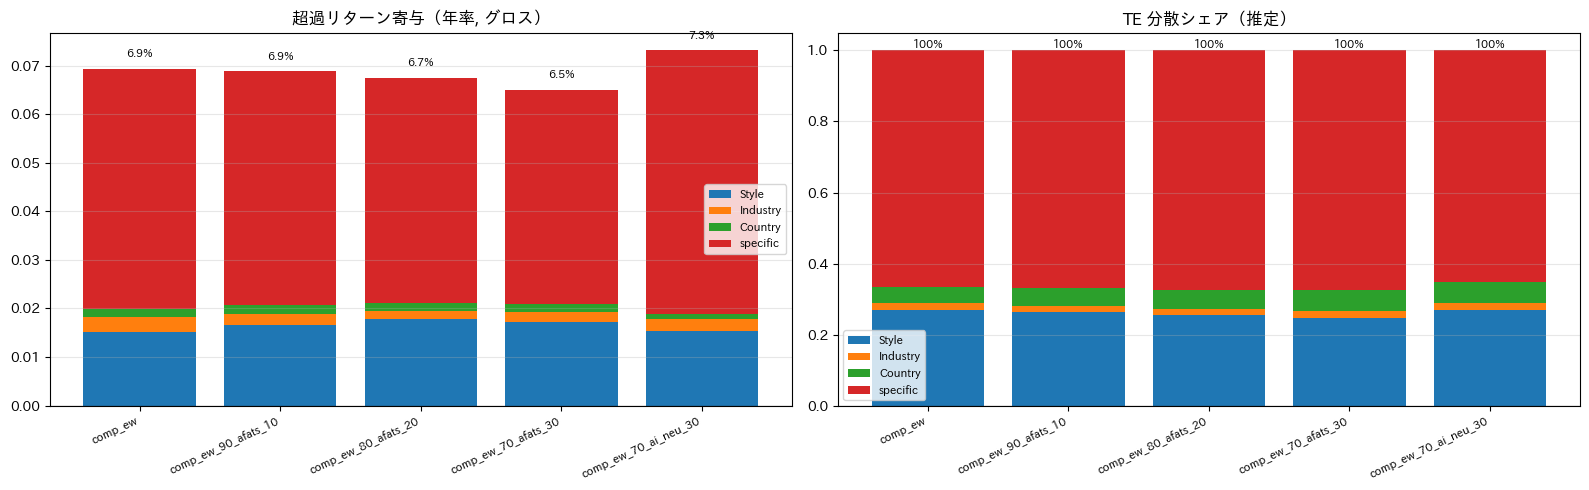

In [8]:
fl = store.factor_list(RISK_MODEL)
fr = store.factor_return(RISK_MODEL)
rows = {}
for n in NAMES:
    groups, _ = factor_attribution(outs[n], fr, fl)
    rd = risk_decomposition(
        outs[n], lambda d: store.factor_covariance(RISK_MODEL, d), fl
    ).loc[:END]
    g = groups.loc[:END].iloc[BURN_IN:]
    rows[n] = {
        **{
            f"寄与 {c}": g[c].mean() * 12
            for c in ["Style", "Industry", "Country", "specific"]
        },
        "寄与 合計": g["excess_gross"].mean() * 12,
        **{
            f"リスク分散シェア {c}": rd[f"share_{c}"].mean()
            for c in ["Style", "Industry", "Country", "specific"]
        },
        "te_factor": rd["te_factor"].mean(),
        "te_specific": rd["te_specific"].mean(),
    }
decomp = pd.DataFrame(rows).T
display(decomp.round(4))
print("comp_ew との差（寄与）")
display(
    (decomp - decomp.loc["comp_ew"])
    .drop(index="comp_ew")[[c for c in decomp.columns if c.startswith("寄与")]]
    .round(4)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
contrib_cols = ["寄与 Style", "寄与 Industry", "寄与 Country", "寄与 specific"]
share_cols = [
    "リスク分散シェア Style",
    "リスク分散シェア Industry",
    "リスク分散シェア Country",
    "リスク分散シェア specific",
]
x = np.arange(len(decomp))
for ax, cols, title, fmt in [
    (axes[0], contrib_cols, "超過リターン寄与（年率, グロス）", lambda v: f"{v:.1%}"),
    (axes[1], share_cols, "TE 分散シェア（推定）", lambda v: f"{v:.0%}"),
]:
    pos = np.zeros(len(decomp))
    neg = np.zeros(len(decomp))
    for c in cols:
        v = decomp[c].to_numpy()
        base = np.where(v >= 0, pos, neg)
        ax.bar(x, v, bottom=base, label=c.split(" ")[-1])
        pos += np.where(v >= 0, v, 0)
        neg += np.where(v < 0, v, 0)
    tot = decomp[cols].sum(axis=1).to_numpy()
    for i, t in enumerate(tot):
        ax.text(i, pos[i] + 0.002, fmt(t), ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x, decomp.index, rotation=25, ha="right", fontsize=8)
    ax.set_title(title)
    ax.axhline(0, color="k", linewidth=0.8)
    ax.grid(axis="x", visible=False)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 8. 制約なしの Q5 等ウェイトとの比較（実現率）

In [9]:
start_d, end_d = first.rebalance_dates.min(), END
univ = store.universe(start_d, end_d)
bm_w = store.benchmark(BENCHMARK, start_d, end_d)
rtn_usd = store.returns(RISK_MODEL, "rtn_usd", start_d, None)
bm_ret = portfolio_returns(bm_w, rtn_usd)
rows = {}
for n in NAMES:
    q = quantile_analysis(
        store.alpha(SCORE_PATH[n], start_d, end_d), rtn_usd, univ, n_quantiles=5
    )
    r = q.returns[q.top].loc[:END].iloc[BURN_IN:]
    s = performance_summary(
        r, bm_ret.reindex(r.index), q.turnover[q.top].reindex(r.index)
    )
    rows[n] = {
        "Q5 EW 超過（制約なし）": s["active_return"],
        "Q5 EW IR": s["information_ratio"],
        "Q5 EW 回転率": s["turnover_annual"],
        "最適化 グロス超過": tbl.loc[n, "超過 グロス"],
        "最適化 IR": tbl.loc[n, "IR コスト後"],
        "実現率": tbl.loc[n, "超過 グロス"] / s["active_return"],
    }
display(pd.DataFrame(rows).T.round(3))

,Q5 EW 超過（制約なし）,Q5 EW IR,Q5 EW 回転率,最適化 グロス超過,最適化 IR,実現率
comp_ew,0.134,1.187,4.049,0.066,0.927,0.494
comp_ew_90_afats_10,0.133,1.167,4.053,0.066,0.905,0.496
comp_ew_80_afats_20,0.133,1.160,4.038,0.065,0.865,0.490
comp_ew_70_afats_30,0.124,1.072,4.014,0.063,0.818,0.510
comp_ew_70_ai_neu_30,0.147,1.292,4.333,0.071,0.993,0.485


## 所見

**1. afats 複合は制約付き最適化で comp_ew を上回らない。afats の比率を上げるほど単調に悪化する。**
（〜202606、バーンイン後）

| | comp_ew | 90:10 | 80:20 | 70:30 |
| --- | --- | --- | --- | --- |
| グロス超過 | 6.6% | 6.6% | 6.5% | 6.3% |
| 税後超過 | 4.3% | 4.3% | 4.2% | 4.0% |
| IR（コスト後） | 0.93 | 0.91 | 0.87 | 0.82 |
| IR（税後） | 0.69 | 0.68 | 0.64 | 0.61 |
| 実現 TE | 6.1% | 6.2% | 6.4% | 6.6% |

リターンはほぼ同じか少し下がり、実現 TE が増える分だけ IR が下がる（推定 TE は全系列 4.9% で同じなので、実現/推定比が 1.24 → 1.34 に悪化）。
回転率・コスト・税ドラッグはほぼ同じで、悪化の原因は売買ではなく銘柄選択側。

**2. comp_ew との差は統計的にゼロ。** 月次超過の差の NW t 値はグロスで −0.11 / −0.26 / −0.42、税後で −0.05 / −0.22 / −0.33。
差の勝率は 48〜49%。comp_ew との超過リターン相関は 0.99 / 0.97 / 0.92。80:20 でも保有の片道差は平均 14%（直近 12 か月は 21%）あり、
ポートフォリオはある程度変わっているが、成績の差にはなっていない。
参考の `comp_ew_70_ai_neu_30` は差 +0.4%/年（グロス）・t 0.91 で、こちらも有意ではないが方向は正。

**3. 期間によって勝ち負けが入れ替わり、安定しない。** afats は 2014、2022–2023、2025 に comp_ew を上回る（70:30 で +3〜4%/年）一方、
2017–2021 と 2026 年上半期に下回る（70:30 で 2020 年 −4.4%、2026 年 −5.1%）。前半（2014–2019）は IR を下げ、後半（2020–）は概ね横ばい。
バリュー的な性格（割安株）なので、バリューが効いた局面だけ上乗せになっている。

**4. 上乗せの中身は Style 寄与で、specific 寄与は削っている。** comp_ew 比の寄与差（年率）は 80:20 で Style +0.25%、specific −0.31%、70:30 で Style +0.20%、specific −0.54%。
afats がスタイル（バリュー系）を足す代わりに、comp_ew の銘柄固有の選択力を薄めている。BM 加重アルファも 0.05 → 0.09（80:20）→ 0.12（70:30）と上がり、
高スコア銘柄が BM の中核銘柄に寄る傾向が少し出る（中立化前の AI スコアと同じ方向だが、程度は小さい）。

**5. 制約なし評価との整合。** `01_evaluation` でも afats 80:20 の改善は IC（t 7.0 → 7.5）や Q5 − Q1 の IR（1.15 → 1.25）に出ていた一方、
**Q5 EW 超過は comp_ew とほぼ同じ**（13.1% vs 13.0%、IR 1.158 vs 1.165）だった。改善はおもにスコア下位（ショート側）の識別で、
long-only の最適化には乗らない。本ノートブック §8 の USD 建て Q5 EW でも 13.3% vs 13.4% と差は無く、実現率（約 49%）も comp_ew と同じ。

**結論**: afats（Theil–Sen 型 Agnostic、中立化版）は、long-only・TE 5% の最適化では comp_ew への上乗せにならない。
暫定スコアへの組み込みは見送り、候補は引き続き `comp_ew_70_ai_neu_30` 系統とするのが妥当。

**次のステップ案**
- afats をショート側の除外フィルタ（下位 20% を投資対象から外す）として使い、long-only でも下位側の識別を活かせるか確認する。
- 12 か月平均版（`comp_ew_*_afats12_*`）は制約なしでも afats と同等以下なので、最適化に回す優先度は低い。